In [ ]:
#########################################################
### Author: Spenser
### Date: 24 Dec 2025
### Description: Test case of the pipeline using a GG parcel

#########################################################

In [1]:
### Import Modules
#Path
from pathlib import Path
import sys
import os 

##  Attributes 
# Note: __file__ global doesnt work in juypter, so opting for os.path
proj_fname = Path(os.path.abspath('')).parents[3].joinpath('grass-projects/unmarkedgraves-test/gg_parcel').resolve()
historic_fname = Path(os.path.abspath('')).joinpath(r'Duval_Sites.shp').resolve()
lidar_fname = Path(os.path.abspath('')).joinpath(r'USGS_LPC_FL_Peninsular_FDEM_2018_D19_DRRA_LID2019_218756_E.las').resolve()

# Import the Model
try:
    from unmarked_graves_pipeline import UnmarkedGraves
except ImportError:
    sys.path.append("..")
    from unmarked_graves_pipeline import UnmarkedGraves

In [2]:
### Running as Grass Jupyter 
ug = UnmarkedGraves()

## Setup Env
ug.setup_grass_env(lidar_fname= lidar_fname
                   ,proj_path=proj_fname)

## Ensuring Grass Jupyter is initialized
ug.gj.init(proj_fname)

Historical Site Buffer is complete. Find it in Grass GIS under file name 
 Duval_Sites_*_buffered 


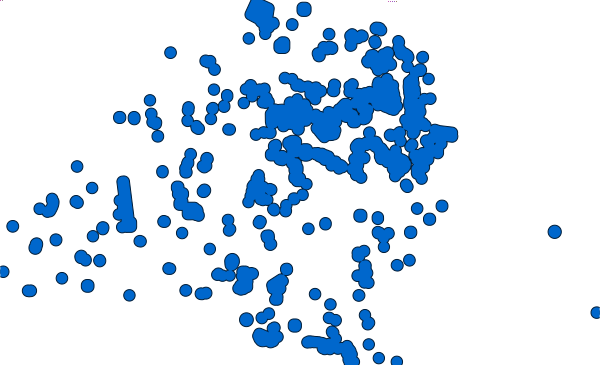

In [3]:
### Historical Buffer
## Creating the buffer
ug.historical_sites_check(historical_file = historic_fname)

## Display the 1/4 and 1/2 mi buffers
gg_hist_map = ug.gj.Map()

# 1/4 mi buffer
gg_hist_map.d_vect(map=f'{historic_fname.stem}_quart_mi_buffered')

# 1/2 mi buffer
gg_hist_map.d_vect(map=f'{historic_fname.stem}_half_mi_buffered')

# Display
gg_hist_map.show()

In [ ]:
### Elevation 
## Running Elevation Check
ug.elevation_check()

## Display LiDAR File and Points of Interest
gg_elev_map = ug.gj.Map()
# LiDAR File
gg_elev_map.d_rast(map= f'{lidar_fname.stem[-15:]}_mean_neighbor')

# Points of Interest
gg_elev_map.d_rast(map='diff_fin_wide')

# Display
gg_elev_map.show()


In [ ]:
### Topology 
ug.topology_check(low_memory= True)

## Display Topology Layer
gg_topo_map = ug.gj.Map()

# Pit Basin
gg_topo_map.d_rast(map='pit_basin_filter_wide')

# Display
gg_topo_map.show()

In [ ]:
### Final Red and Amber Sites
ug.rag_ranking(low_memory= True, shapefile=True)

## Display Red and Amber Sites
gg_ranked_map = ug.gj.Map()

# Add Lidar Background
gg_ranked_map.d_rast(map=f'{lidar_fname.stem[-15:]}_mean_neighbor')
# Red Sites
gg_ranked_map.d_vect(map='red_sites_grow_vect')

# Amber Sites
gg_ranked_map.d_vect(map='amber_sites_grow_vect')

# Display
gg_ranked_map.show()